# Lab 4 — zadania 1 i 2

Zadanie 1: uczenie przyrostowe na danych większych niż RAM klastra (4×1 GB) oraz porównanie rozmiarów chunków.
Zadanie 2: serializacja modelu (`joblib`), predykcja i macierz pomyłek.


In [1]:
import os
import time

import dask
import joblib
import matplotlib.pyplot as plt
import numpy as np
from dask.distributed import Client, KilledWorker
from dask_ml.datasets import make_classification
from dask_ml.model_selection import train_test_split
from dask_ml.preprocessing import StandardScaler
from dask_ml.wrappers import Incremental
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

DATADIR = "./data"
os.makedirs(DATADIR, exist_ok=True)


def make_client():
    # 4 workery x 1 GB = 4 GB RAM klastra; zbiór ~6 GB przekracza tę pamięć.
    return Client(n_workers=4, threads_per_worker=1, memory_limit="1GB")


client = make_client()
client

C:\Users\kaczo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 64624 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:64624/status,
Dashboard: http://127.0.0.1:64624/status,Workers: 4
Total threads: 4,Total memory: 3.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:64627,Workers: 0
Dashboard: http://127.0.0.1:64624/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:64650,Total threads: 1
Dashboard: http://127.0.0.1:64652/status,Memory: 0.93 GiB
Nanny: tcp://127.0.0.1:64630,


**Zadanie 1.** Zbiór $3\,000\,000 \times 250 \times 8\,B \approx 6\,GB$. Kolejność eksperymentów: mały → średni → duży chunk. Przy `n//4` chunk ma ~1.5 GB i często kończy się `KilledWorker` przy limicie 1 GB/worker — to też wynik eksperymentu.


In [2]:
n, d = 3_000_000, 250
classes = np.array([0, 1])
chunk_divisors = [
    ("mały (n//300)", n // 300),
    ("średni (n//30)", n // 30),
    ("duży (n//4)", n // 4),
]

results = []
best = None

for label, chunk_rows in chunk_divisors:
    print(f"\n=== {label}: chunk_rows={chunk_rows} ===")
    try:
        X_inc, y_inc = make_classification(
            n_samples=n,
            n_features=d,
            chunks=chunk_rows,
            flip_y=0.2,
            random_state=42,
        )
        X_train, X_test, y_train, y_test = train_test_split(
            X_inc, y_inc, test_size=0.2, shuffle=True, random_state=42
        )

        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        est = SGDClassifier(loss="log_loss", penalty="l2", tol=1e-3, random_state=42)
        inc = Incremental(est, scoring="accuracy")

        t0 = time.perf_counter()
        inc.fit(X_train, y_train, classes=classes)
        test_acc = float(inc.score(X_test, y_test))
        elapsed = time.perf_counter() - t0

        row = {
            "chunk": label,
            "chunk_rows": chunk_rows,
            "nchunks": int(X_inc.numblocks[0]),
            "X_GB": round(X_inc.nbytes / 1024**3, 2),
            "test_acc": test_acc,
            "seconds": round(elapsed, 2),
            "status": "ok",
        }
        results.append(row)
        print(row)

        if best is None or elapsed < best["seconds"]:
            best = {
                "seconds": elapsed,
                "label": label,
                "inc": inc,
                "X_test": X_test,
                "y_test": y_test,
                "X_train": X_train,
                "y_train": y_train,
                "test_acc": test_acc,
            }
    except Exception as exc:
        row = {
            "chunk": label,
            "chunk_rows": chunk_rows,
            "status": type(exc).__name__,
            "error": str(exc)[:200],
        }
        results.append(row)
        print(row)
        # Po KilledWorker odtwarzamy klaster, żeby kolejne eksperymenty mogły się wykonać.
        try:
            client.close()
        except Exception:
            pass
        client = make_client()

print("\nPodsumowanie eksperymentów:")
for row in results:
    print(row)

if best is None:
    raise RuntimeError("Żaden przebieg nie zakończył się sukcesem.")

print(
    f"\nNajszybszy udany chunk: {best['label']} "
    f"({best['seconds']:.2f} s), test_acc={best['test_acc']:.4f}"
)

inc = best["inc"]
X_train, X_test = best["X_train"], best["X_test"]
y_train, y_test = best["y_train"], best["y_test"]


=== mały (n//300): chunk_rows=10000 ===


{'chunk': 'mały (n//300)', 'chunk_rows': 10000, 'nchunks': 300, 'X_GB': 5.59, 'test_acc': 0.6893833333333333, 'seconds': 25.51, 'status': 'ok'}

=== średni (n//30): chunk_rows=100000 ===


2026-10-29 16:26:44,880 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


2026-10-29 16:26:49,501 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


2026-10-29 16:26:50,460 - distributed.nanny - WARNING - Restarting worker (status=Status.running)


...

2026-10-29 16:27:42,490 - distributed.scheduler - ERROR - Task ('normal-5a3a37504676d7dc2a37bbe4a1337e73', 1, 0) marked as failed because 4 workers died while trying to run it


{'chunk': 'duży (n//4)', 'chunk_rows': 750000, 'status': 'KilledWorker', 'error': "Attempted to run task ('normal-5a3a37504676d7dc2a37bbe4a1337e73', 1, 0) on 4 different workers, but all those workers died while running it. The last worker that attempt to run the task was tcp://127."}


2026-10-29 16:27:46,524 - distributed.nanny - WARNING - Worker process still alive after 4.0 seconds, killing


C:\Users\kaczo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\distributed\node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 54843 instead
  warnings.warn(



Podsumowanie eksperymentów:
{'chunk': 'mały (n//300)', 'chunk_rows': 10000, 'nchunks': 300, 'X_GB': 5.59, 'test_acc': 0.6893833333333333, 'seconds': 25.51, 'status': 'ok'}
{'chunk': 'średni (n//30)', 'chunk_rows': 100000, 'status': 'KilledWorker', 'error': "Attempted to run task ('mean_chunk-4124ed65cf1faf6b1e10c681abe2071a', 13, 0) on 4 different workers, but all those workers died while running it. The last worker that attempt to run the task was tcp:/"}
{'chunk': 'duży (n//4)', 'chunk_rows': 750000, 'status': 'KilledWorker', 'error': "Attempted to run task ('normal-5a3a37504676d7dc2a37bbe4a1337e73', 1, 0) on 4 different workers, but all those workers died while running it. The last worker that attempt to run the task was tcp://127."}

Najszybszy udany chunk: mały (n//300) (25.51 s), test_acc=0.6894


**Zadanie 2.** Zapis `joblib`, wczytanie do nowej zmiennej, predykcja na `X_test` oraz macierz pomyłek (`dask.compute` na `y_test` i `y_pred`).


Model zapisany w: ./data\zad1_incremental_sgd.joblib


Macierz pomyłek:
 [[208846  91080]
 [ 95290 204784]]


Dokładność wczytanego modelu: 0.6894


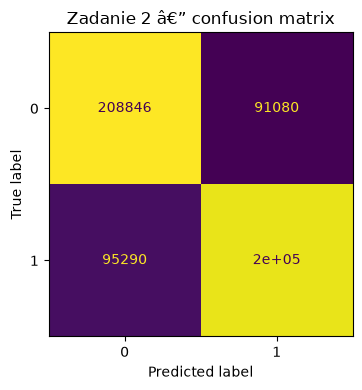

In [3]:
MODEL_PATH = os.path.join(DATADIR, "zad1_incremental_sgd.joblib")
joblib.dump(inc, MODEL_PATH)
print(f"Model zapisany w: {MODEL_PATH}")

loaded_model = joblib.load(MODEL_PATH)
y_pred = loaded_model.predict(X_test)

y_true_np, y_pred_np = dask.compute(y_test, y_pred)
cm = confusion_matrix(y_true_np, y_pred_np)
print("Macierz pomyłek:\n", cm)
print(f"Dokładność wczytanego modelu: {loaded_model.score(X_test, y_test):.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
ax.set_title("Zadanie 2 — confusion matrix")
plt.tight_layout()
plt.show()

In [4]:
client.close()